# PA3 · Task 3 · Offline experiments on the supplied rollouts (Steps 1, 2, 3, 5, 6)

**What this notebook does.**
1. Loads both supplied folders, checks that every file joins and every token list lines up, and compares the totals with the supplied README.
2. Splits each dataset (sorted IDs, `default_rng(6304)`): 200 development + 800 held-out questions; makes the ten random orders of the 32 rollouts.
3. Groups and grades every answer: `math-verify` 0.9.0 for MATH, MathVista's official rules (with the released testmini metadata) for MathVista; missing answers → `NO_ANSWER`.
4. Runs every selection rule at N = 1, 2, 4, 8, 16, 32 over the ten orders; oracle coverage; the sampling-vs-selection decomposition; paired bootstrap intervals.
5. Signal analysis at N = 32: length / score / correctness associations, confidence–vision correlation, tokenwise vs rollout-level fusion.
6. Adaptive stopping: thresholds chosen on development, frozen, then evaluated on held-out.

**Settings:** Accelerator **None (CPU)** is enough. Internet **On** (installs `math-verify`, downloads MathVista's question metadata). About 20–40 min.
**Attach:** `pa3-task3` and your **`atml-pa3-data`** dataset (the Drive folder, uploaded unchanged). To rerun only the analysis, also attach this notebook's earlier output: the graded rollouts in `t3/prep/` are reused (saves about 15 min).

**Run with "Save Version → Save & Run All".** **How to read the output:** `PASS / FAIL / OBSERVE`, then the **expected** and **actual** lines.

In [1]:
# S1. Find the Task 3 code (attached Kaggle dataset, or a clone of your GitHub repo) and copy it to /tmp.
import os, sys, glob, json, time, shutil, subprocess
from pathlib import Path
SESSION_START = time.time()     # Kaggle's 12-hour limit counts from about now

REPO_URL = ""        # optional: your public GitHub repo URL, used only if no code dataset is attached
REQUIRED_CODE_VERSION = "2026.11.03.2"   # this notebook needs this code version or newer
NEED_GPU = False
CODE = Path("/tmp/pa3_task3_code")

def code_version(root):
    import re
    try:
        m = re.search(r'CODE_VERSION\s*=\s*"([^"]+)"', (Path(root) / "common" / "__init__.py").read_text())
        return m.group(1) if m else "0 (no version stamp)"
    except FileNotFoundError:
        return "0 (no version stamp)"

hits = sorted({Path(p).parents[1] for p in glob.glob("/kaggle/input/**/task3/t3_offline.py", recursive=True)},
              key=code_version, reverse=True)
for h in hits:
    print(f"found code copy: {h}  (version {code_version(h)})")
if CODE.exists():
    shutil.rmtree(CODE)
if hits:
    if code_version(hits[0]) < REQUIRED_CODE_VERSION:
        raise SystemExit(f"The newest attached code is version {code_version(hits[0])}, but this notebook needs "
                         f"{REQUIRED_CODE_VERSION}. Upload the latest pa3-task3.zip as a new dataset version and re-attach it.")
    shutil.copytree(hits[0], CODE)
    print("using:", hits[0])
elif REPO_URL:
    subprocess.run(["git", "clone", "-q", REPO_URL, str(CODE)], check=True)
    print("code cloned from", REPO_URL)
else:
    raise SystemExit("Attach the pa3-task3 dataset (or set REPO_URL) and re-run this cell.")
sys.path.insert(0, str(CODE))
os.chdir(CODE)
CODE_COPIES = [str(h) for h in hits]
def inputs(pattern):
    """Files matching `pattern` in the ATTACHED inputs only (never inside a copy of the code)."""
    return [p for p in glob.glob(pattern, recursive=True) if not any(p.startswith(c + "/") for c in CODE_COPIES)]
from common.utils import Checks, human_bytes, dir_size_bytes, read_json, read_jsonl
CHK = Checks()
CHK.check(code_version(CODE) >= REQUIRED_CODE_VERSION, "code version in use", f">= {REQUIRED_CODE_VERSION}", code_version(CODE))
try:
    smi = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], capture_output=True, text=True)
    GPUS = [l.strip() for l in smi.stdout.strip().splitlines() if l.strip()]
except FileNotFoundError:
    GPUS = []
if NEED_GPU:
    CHK.check(len(GPUS) >= 1, "GPU visible", "GPU T4 (Settings -> Accelerator)", GPUS or "no GPU: is the accelerator switched on?")
else:
    CHK.observe("accelerator", GPUS or "CPU only (enough for this notebook)")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "math-verify==0.9.0"], check=True)
import importlib.metadata as md
vers = {p: md.version(p) for p in ["torch", "transformers", "numpy", "pandas", "pyarrow", "scipy", "math-verify"]}
CHK.observe("library versions", vers)
CHK.check(vers["math-verify"] == "0.9.0", "answer-equivalence scorer pinned (math-verify)", "0.9.0", vers["math-verify"])
# the supplied rollouts, attached as a Kaggle dataset (ATML-PA3-Data, unchanged)
from task3 import t3_data as D
FOLDERS = D.find_folders(["/kaggle/input"])
CHK.check(set(FOLDERS) == {"math", "mathvista"}, "supplied data attached (qwen25-math/, qwen25vl-mathvista/)", "both folders",
          {k: str(v) for k, v in FOLDERS.items()} or "not found: attach your atml-pa3-data dataset")
DATA_ROOT = str(Path(FOLDERS["math"]).parent) if "math" in FOLDERS else "/kaggle/input"
for k, v in FOLDERS.items():
    CHK.observe(f"{k} files", {f.name: human_bytes(f.stat().st_size) for f in sorted(Path(v).glob("*.parquet"))})
WORK = Path("/kaggle/working"); T3 = WORK / "t3"; T3.mkdir(parents=True, exist_ok=True)

found code copy: /kaggle/input/datasets/zylah628/pa3-task3/pa3-task3  (version 2026.11.03.2)
using: /kaggle/input/datasets/zylah628/pa3-task3/pa3-task3
[PASS   ] code version in use
          expected: >= 2026.11.03.2
          actual  : 2026.11.03.2
[OBSERVE] accelerator
          actual  : CPU only (enough for this notebook)
[OBSERVE] library versions
          actual  : {'torch': '2.11.0+cpu', 'transformers': '5.20.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'pyarrow': '23.0.1', 'scipy': '1.16.3', 'math-verify': '0.9.0'}
[PASS   ] answer-equivalence scorer pinned (math-verify)
          expected: 0.9.0
          actual  : 0.9.0
[PASS   ] supplied data attached (qwen25-math/, qwen25vl-mathvista/)
          expected: both folders
          actual  : {'math': '/kaggle/input/datasets/zylah628/atml-pa3-data/ATML-PA3-Data/qwen25-math', 'mathvista': '/kaggle/input/datasets/zylah628/atml-pa3-data/ATML-PA3-Data/qwen25vl-mathvista'}
[OBSERVE] math files
          actual  : {'generations.parquet'

In [2]:
# S2. Preparation: load, check, split, order, group and grade (or reuse an attached earlier preparation).
prev = sorted(inputs("/kaggle/input/**/t3/prep/scorer.json"))
if (T3 / "prep" / "scorer.json").exists():
    print("preparation already in the working directory")
elif prev:
    shutil.copytree(Path(prev[-1]).parent, T3 / "prep"); print("reused the attached preparation:", Path(prev[-1]).parent)
else:
    meta = sorted(inputs("/kaggle/input/**/t3/prep/mathvista_meta.json"))
    cmd = [sys.executable, "-u", "-m", "task3.t3_offline", "prep", "--data_root", DATA_ROOT, "--out", str(T3)] + \
          (["--mathvista_meta", meta[-1]] if meta else [])
    r = subprocess.run(cmd, cwd=CODE, capture_output=True, text=True)
    print(r.stdout[-20000:]); print(r.stderr[-4000:] if r.returncode else "")
    CHK.check(r.returncode == 0 and "0 FAIL" in r.stdout, "preparation finished and its checks passed", "0 FAIL",
              [l for l in r.stdout.splitlines() if l.startswith("====")][-1:] or r.returncode)
CHK.observe("scorer (fixed before any evaluation)", read_json(T3 / "prep" / "scorer.json"))

[PASS   ] math: supplied folder found (qwen25-math/)
          expected: qwen25-math
          actual  : /kaggle/input/datasets/zylah628/atml-pa3-data/ATML-PA3-Data/qwen25-math
[PASS   ] math: 32,000 rollouts in every file
          expected: 32000
          actual  : (32000, 32000)
[PASS   ] math: every rollout joins across files on ['dataset', 'sample_id', 'rollout_id']
          expected: True
          actual  : (True, None)
[PASS   ] math: 1,000 questions x rollout IDs 0..31
          expected: 1000 x 32
          actual  : 1000 questions, counts [32]
[PASS   ] math: token lists aligned (token IDs = logp = kl_u_p = n_generated_text_tokens)
          expected: all 32,000
          actual  : 32,000 aligned
[PASS   ] math: totals match the supplied README
          expected: {'retained_tokens': 20742094, 'capped': 523, 'null_extracted': 521}
          actual  : {'retained_tokens': 20742094, 'capped': 523, 'null_extracted': 521}
  math: graded 200 / 1000 questions
  math: graded 400 /

In [3]:
# S3. Analysis: every rule x budget x order, signals, adaptive stopping (thresholds from development only).
#     One process per dataset, so a problem in one cannot hide the other's results.
ANALYSIS_OK = True
for name in ["math", "mathvista"]:
    t0 = time.time()
    r = subprocess.run([sys.executable, "-u", "-m", "task3.t3_offline", "analyze", "--out", str(T3), "--datasets", name],
                       cwd=CODE, capture_output=True, text=True)
    print(r.stdout[-30000:])
    if r.returncode:
        print(f"return code {r.returncode}" + (" (killed: out of memory?)" if r.returncode in (-9, 137) else "")); print(r.stderr[-4000:])
    ok = r.returncode == 0 and "0 FAIL" in r.stdout
    ANALYSIS_OK &= ok
    CHK.check(ok, f"{name}: analysis finished and its checks passed", "0 FAIL",
              [l for l in r.stdout.splitlines() if l.startswith("==== ") and "PASS" in l][-1:] or f"return code {r.returncode}")
    CHK.observe(f"{name}: analysis time", f"{(time.time() - t0) / 60:.1f} min")

==== math: 1000 questions
  selection: 200 / 1000 questions (4 s)
  selection: 400 / 1000 questions (8 s)
  selection: 600 / 1000 questions (13 s)
  selection: 800 / 1000 questions (17 s)
  selection: 1000 / 1000 questions (21 s)
[PASS   ] math: at N = 1 every rule returns the only candidate
          expected: True
          actual  : True
[PASS   ] math: no rule is ever correct without a correct candidate (accuracy <= coverage)
          expected: True
          actual  : True
[PASS   ] math: oracle coverage never decreases along a nested order
          expected: True
          actual  : True
method  FirstAns    SC  MaxLogProb  MaxSelfCert  SelfCert+RWC  Shortest
N                                                                      
1           64.4  64.4        64.4         64.4          64.4      64.4
2           64.4  64.4        65.8         66.8          66.8      65.3
4           64.4  69.2        67.2         68.8          69.7      65.2
8           64.4  71.8        67.5   


==== MATH (Qwen2.5-3B): method comparison (held-out)
                       method  acc N=4 (%)  tokens N=4 vs SC N=4 (pp) [95% CI]  acc N=32 (%)  tokens N=32 vs SC N=32 (pp) [95% CI]
                     FirstAns         64.4       669.8       -4.8 [-5.7, -4.1]          64.4        669.8       -9.4 [-11.0, -8.0]
                           SC         69.2      2679.7                                  73.8      21347.0                         
                   MaxLogProb         67.2      2679.7       -2.0 [-2.9, -1.1]          64.0      21347.0       -9.8 [-12.4, -7.4]
                  MaxSelfCert         68.8      2679.7       -0.4 [-1.3, +0.5]          70.6      21347.0        -3.2 [-5.5, -0.8]
                 SelfCert+RWC         69.7      2679.7       +0.5 [-0.1, +1.2]          75.6      21347.0        +1.8 [+0.7, +2.9]
                     Shortest         65.2      2679.7       -4.0 [-5.1, -3.0]          62.4      21347.0      -11.4 [-14.1, -9.0]
oracle coverage (upper bound)

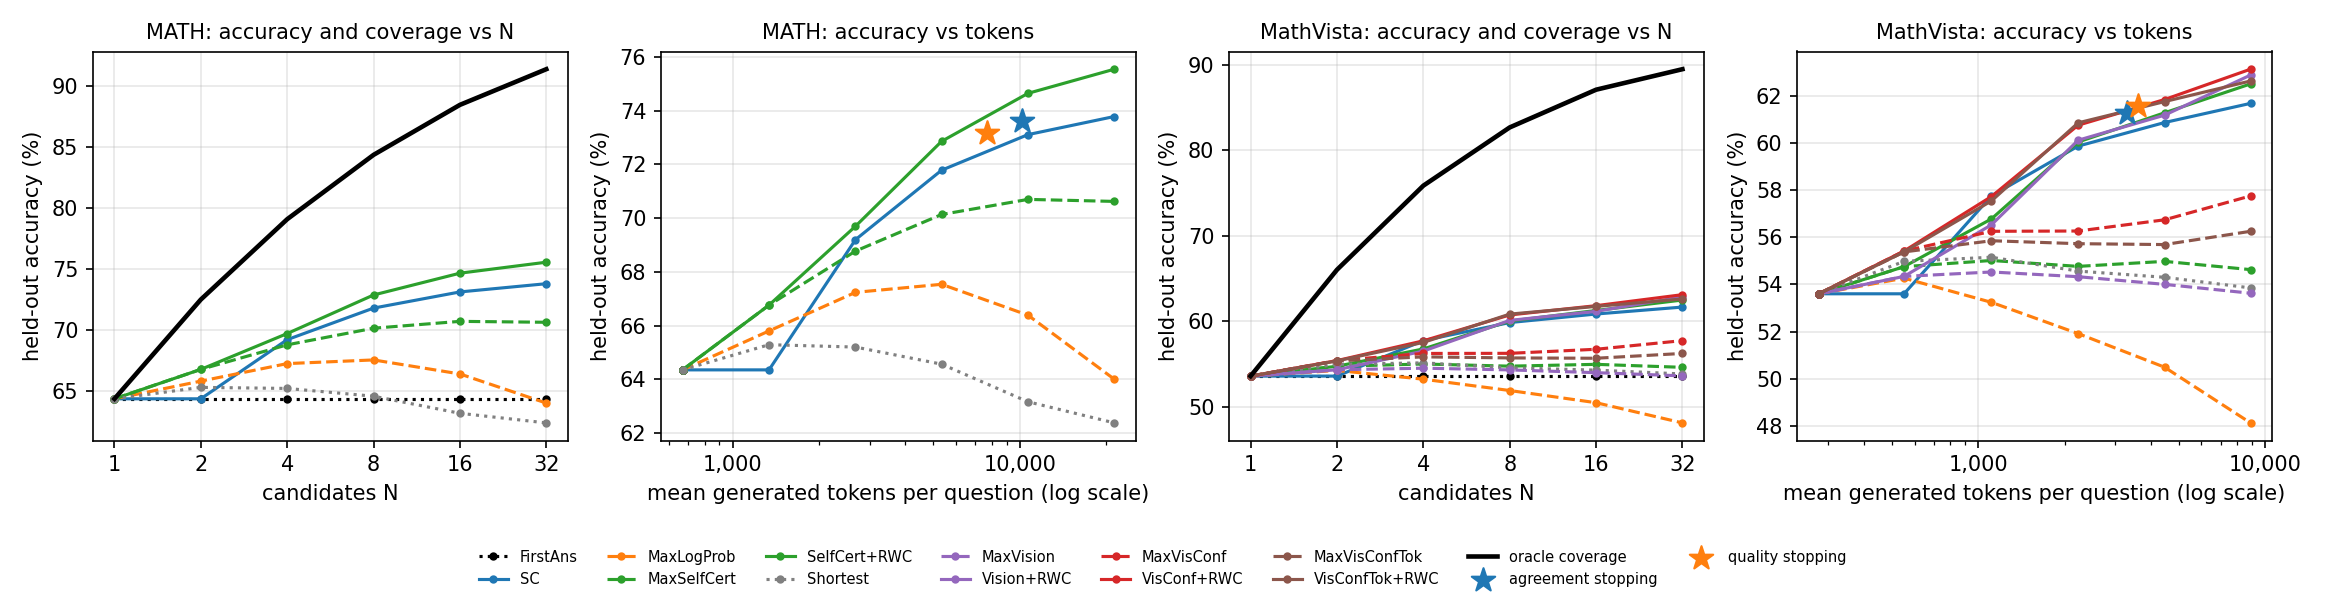

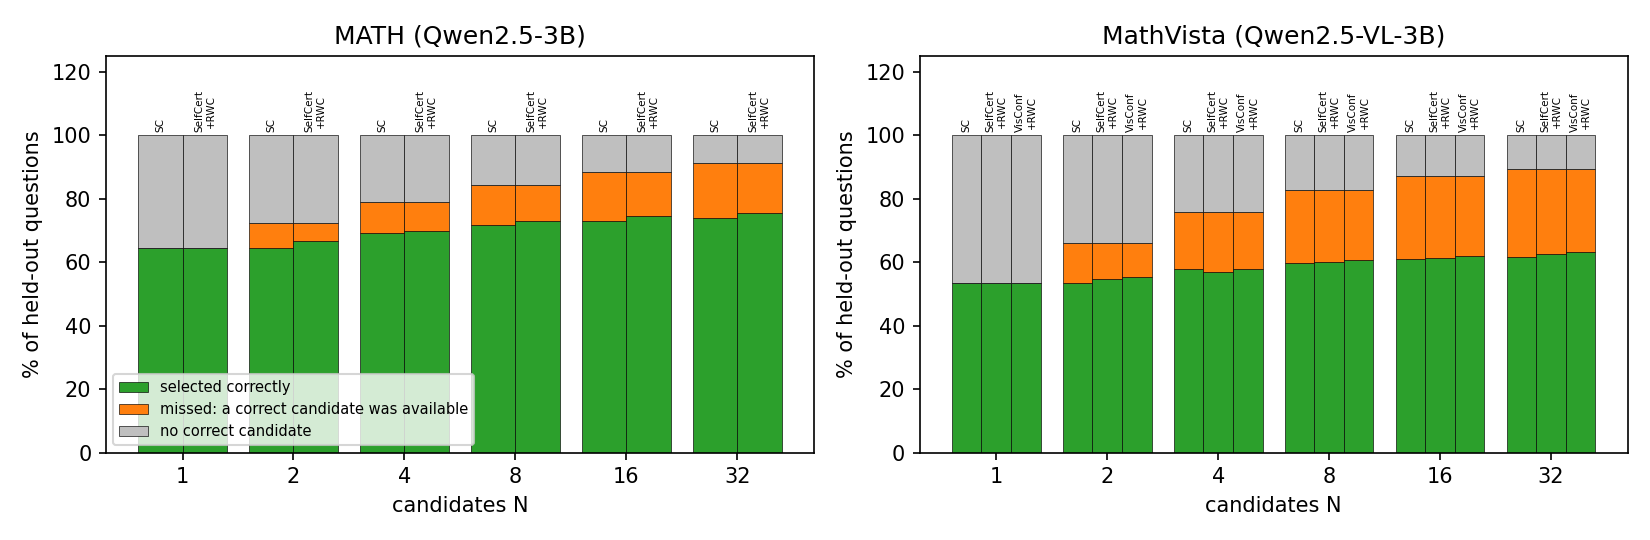

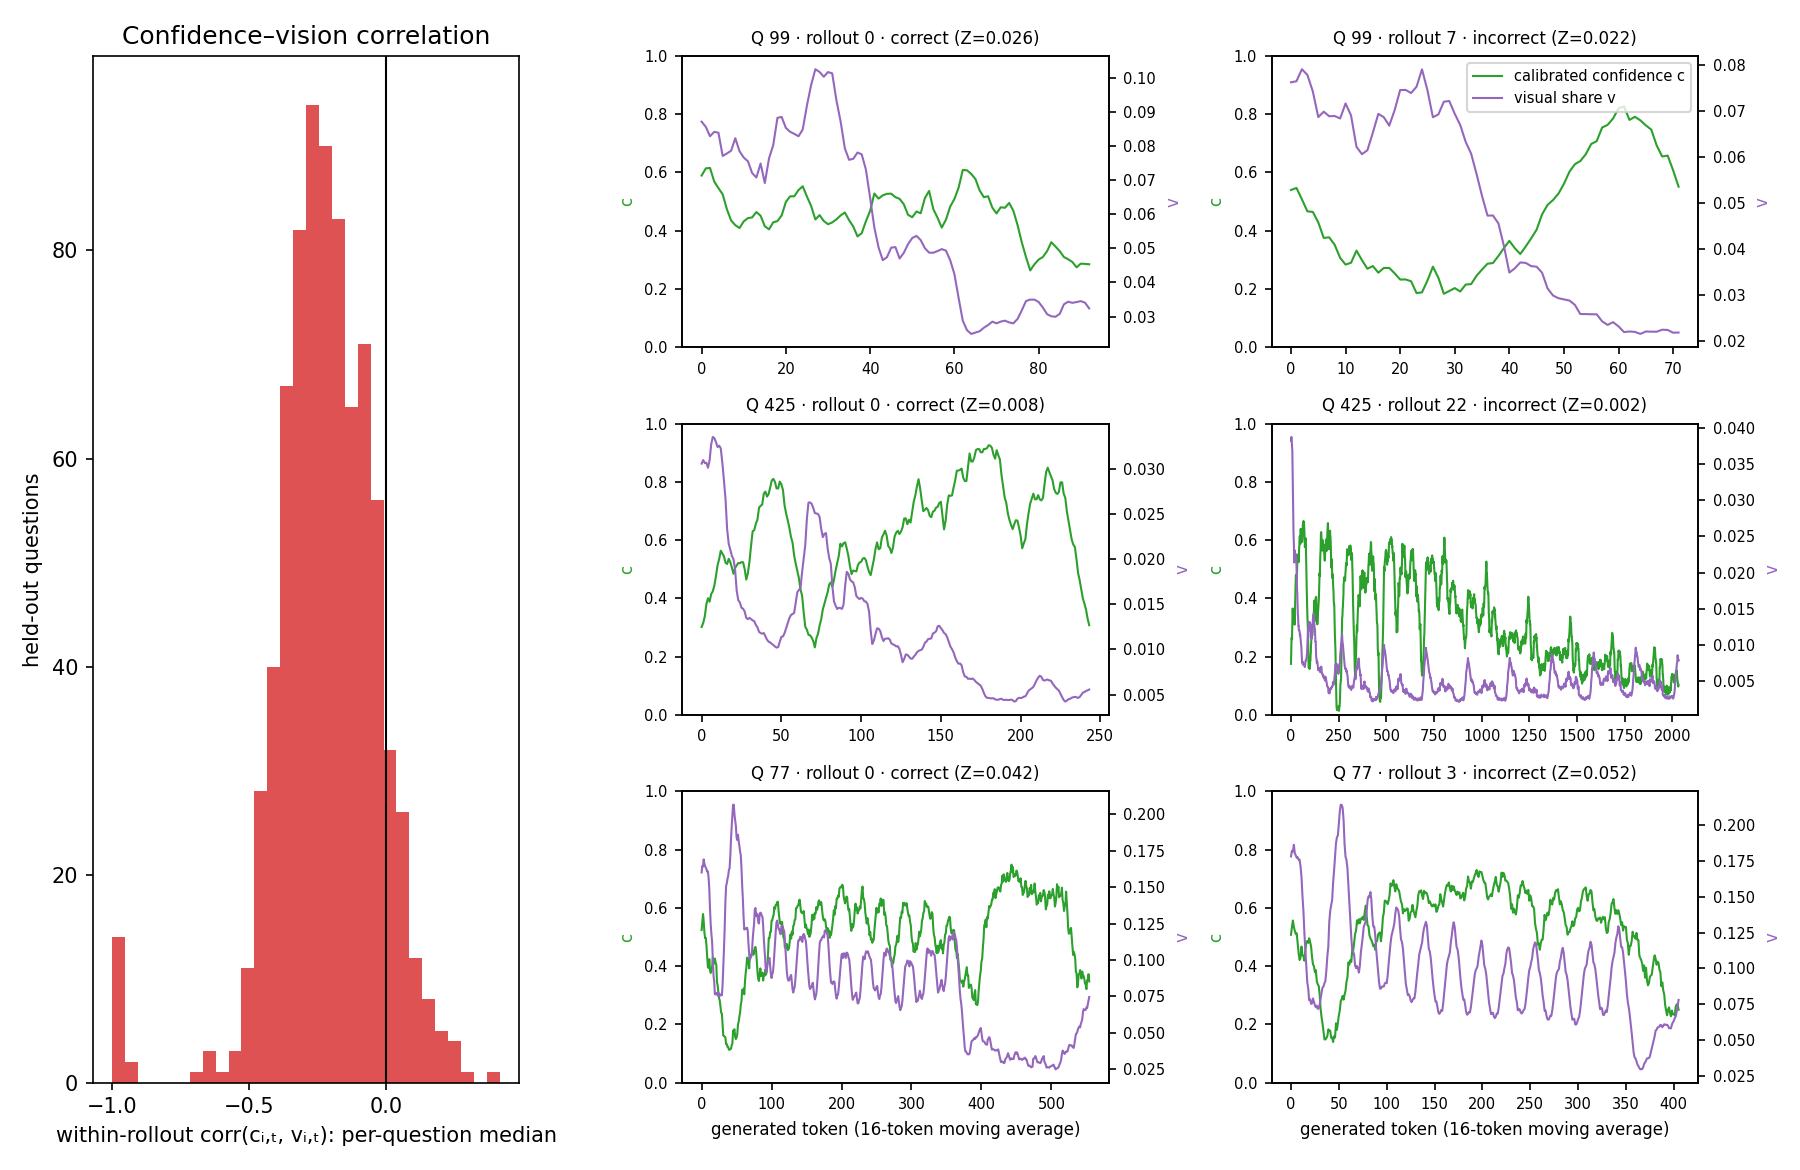

In [4]:
# S4. Tables and figures (built only from the saved results).
from task3 import t3_report as R
import pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
REP = T3 / "report"
R.build(T3, REP)
for n in [n for n in ["math", "mathvista"] if (REP / f"t3_{n}_decomposition.csv").exists()]:
    print(f"\n==== {n}: sampling vs selection (held-out, % of questions)")
    print(pd.read_csv(REP / f"t3_{n}_decomposition.csv").round(1).to_string(index=False))
    print(f"\n==== {n}: signals at N = 32 (within question)")
    print(pd.read_csv(REP / f"t3_{n}_signals.csv").round(3).to_string(index=False))
    print(f"\n==== {n}: adaptive stopping (held-out)")
    print(json.dumps(read_json(T3 / "analysis" / f"{n}_adaptive_chosen.json"), indent=1))
    print(pd.read_csv(REP / f"t3_{n}_adaptive_heldout.csv").round(3).to_string(index=False))
    print(json.dumps(read_json(T3 / "analysis" / f"{n}_early_stops.json"), indent=1)[:3000])
from IPython.display import Image, display
for f in ["t3_accuracy_curves.png", "t3_failure_decomposition.png", "t3_mathvista_signals.png"]:
    if (REP / f).exists(): display(Image(str(REP / f)))

In [5]:
# S5. Illustrative cases (stated rule: the first held-out questions, in split order, showing each behaviour; order 0).
for n in [n for n in ["math", "mathvista"] if (T3 / "analysis" / f"{n}_examples.json").exists()]:
    ex = read_json(T3 / "analysis" / f"{n}_examples.json")
    print(f"\n==== {n}: selection disagreements (self-consistency vs the main quality rule)")
    print(json.dumps(ex["selection_disagreement"], indent=1, ensure_ascii=False)[:4000])
    print(f"\n==== {n}: premature stops (quality-aware controller)")
    print(json.dumps(ex["premature_stop"], indent=1, ensure_ascii=False)[:4000])


==== math: selection disagreements (self-consistency vs the main quality rule)
[
 {
  "sample_id": "test:2460",
  "gold": "154",
  "votes_top5": {
   "154": 11,
   "58": 11,
   "NO_ANSWER": 3,
   "45": 1,
   "98": 1
  },
  "SC": {
   "rollout": 13,
   "answer": "58",
   "correct": false
  },
  "SelfCert+RWC": {
   "rollout": 23,
   "answer": "154",
   "correct": true
  },
  "fraction_correct_in_pool": 0.34375
 },
 {
  "sample_id": "test:2892",
  "gold": "-71",
  "votes_top5": {
   "0": 4,
   "1": 4,
   "23": 2,
   "-1": 1,
   "NO_ANSWER": 1
  },
  "SC": {
   "rollout": 31,
   "answer": "1",
   "correct": false
  },
  "SelfCert+RWC": {
   "rollout": 24,
   "answer": "0",
   "correct": false
  },
  "fraction_correct_in_pool": 0.0
 },
 {
  "sample_id": "test:2948",
  "gold": "1+\\sqrt 2,\\ 1-\\sqrt 2,\\ 2+\\sqrt 3,\\ 2-\\sqrt 3",
  "votes_top5": {
   "1": 5,
   "1 \\text{ and } 2": 4,
   "2 + \\sqrt{3}, 2 - \\sqrt{3}": 3,
   "2 + \\sqrt{3}, 2 - \\sqrt{3}, \\frac{3 + \\sqrt{13 + 4\\sqrt{3

In [6]:
# S6. Machine-readable results for the GitHub repo: t3_offline_results.zip (no copies of the supplied data).
import zipfile
skip = {"mathvista_tokens.npz"}                       # per-token arrays copied from the supplied files: reproducible, not needed
with zipfile.ZipFile(WORK / "t3_offline_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(T3.rglob("*")):
        if f.is_file() and f.name not in skip and "hf_cache" not in str(f):
            z.write(f, str(f.relative_to(WORK)))
CHK.observe("t3_offline_results.zip", human_bytes((WORK / "t3_offline_results.zip").stat().st_size))
CHK.summary(); CHK.save(WORK / "t3_offline_notebook_checks.json")
print("\nNEXT:", "send this notebook (S2-S5 output) and t3_offline_results.zip." if ANALYSIS_OK else
      "something failed: send this notebook's output as it is.")

[OBSERVE] t3_offline_results.zip
          actual  : 6.15 MB

==== 6 PASS | 0 FAIL | 8 OBSERVE ====

NEXT: send this notebook (S2-S5 output) and t3_offline_results.zip.
